## Model 2: the Er$^{3+}$:LiYF$_4$ Hamiltonian ($4f^{11}$) and its validation

Model 2 is the full $4f^{11}$ configuration of Er$^{3+}$ in LiYF$_4$: 364 states, embedded in 512 dimensions (9 qubits). The parametric Hamiltonian is that of M. A. Couto dos Santos, E. Antic-Fidancev, J. Y. Gesland, J. C. Krupa, M. Lemaître-Blaise and P. Porcher, J. Alloys Compd. **275–277**, 435–441 (1998), [doi:10.1016/S0925-8388(98)00363-6](https://doi.org/10.1016/S0925-8388(98)00363-6). It keeps their $D_{2d}$ approximation to the $S_4$ site:
$$H = \sum_{n=0}^{3} E^n e_n + \alpha L(L+1) + \beta G(G_2) + \gamma G(R_7) + \sum_i T^i t_i + \zeta A_{\rm SO} + \sum_k M^k m_k + \sum_k P^k p_k + B^2_0 C^2_0 + B^4_0 C^4_0 + B^4_4 (C^4_4 + C^4_{-4}) + B^6_0 C^6_0 + B^6_4 (C^6_4 + C^6_{-4}).$$
Free-ion Coulomb, spin-orbit and crystal-field terms have very different strengths (10$^5$, 10$^3$ and 10$^2$ cm$^{-1}$).

Before any DBQA run, the Hamiltonian built with PyCF must reproduce the experimental levels with a residual consistent with the reported $\sigma = 14.6$ cm$^{-1}$. This notebook
1. converts the reported Racah parameters $E^1, E^2, E^3$ to the Slater-Condon $F^k$ used by PyCF,
2. compares the PyCF levels with the experimental and calculated levels of Table 1 of the paper,
3. diagnoses the mismatch that appears, and fixes the Hamiltonian used for Model 2.

In [1]:
import os
import csv
import logging
import pickle

import numpy as np
import matplotlib.pyplot as plt

from qibo import set_backend
from qibo.config import log

from pycf import cfl
from pycf.import_sljm import ImportSLJM

from qibo_dbqa.utils_crystal_field import *

# PyCF source tree with the bundled matrix-element bases (examples/*/matel)
os.environ.setdefault("PYCF_ROOT", os.path.abspath("../../../pycf"))

set_backend("numpy")
log.setLevel(logging.ERROR)
os.makedirs("pdfs_figures", exist_ok=True)
os.makedirs("simulation_results", exist_ok=True)

[Qibo 0.2.14|INFO|2026-10-16 05:40:24]: Using numpy backend on /CPU:0


#### Data from the paper

Table 1 lists, for the lowest 134 Kramers doublets (up to 44 000 cm$^{-1}$), the experimental energy where it was measured and the calculated energy of the authors' fit. The table contains **108** experimental levels; the abstract and Table 2 quote 109, the conclusion 108. The authors' own calculated levels reproduce their stated $\sigma = 14.6$ cm$^{-1}$ with $N=108$ levels and $p=21$ free parameters, $\sigma = \sqrt{\sum \Delta^2/(N-p)}$, which confirms the transcription and the definition of $\sigma$.

In [2]:
with open("data/Er_LiYF4_CoutoDosSantos1998_Table1.csv") as file:
    table = list(csv.DictReader(line for line in file if not line.startswith("#")))
measured = np.array([row["E_exp"] != "" for row in table])
e_exp = np.array([float(row["E_exp"]) for row in table if row["E_exp"]])
e_calc_paper = np.array([float(row["E_calc"]) for row in table])
n_table = len(table)
print(f"{n_table} doublets in Table 1, {measured.sum()} with an experimental energy")

def sigma(residuals, nparameters=21):
    return np.sqrt(np.sum(residuals**2) / (len(residuals) - nparameters))

residuals_paper = e_calc_paper[measured] - e_exp
print(f"paper fit: sigma = {sigma(residuals_paper):.2f} cm^-1, rms = {np.sqrt(np.mean(residuals_paper**2)):.2f} cm^-1")

134 doublets in Table 1, 108 with an experimental energy
paper fit: sigma = 14.63 cm^-1, rms = 13.13 cm^-1


#### Conversion of the parameters

PyCF's `f11cf` basis expresses the Coulomb interaction with the Slater-Condon parameters $F^2, F^4, F^6$. The Racah parameters are related to the reduced $F_k$ by
$E^1 = (70F_2 + 231F_4 + 2002F_6)/9$, $E^2 = (F_2 - 3F_4 + 7F_6)/9$, $E^3 = (5F_2 + 6F_4 - 91F_6)/3$, with $F_2=F^2/225$, $F_4=F^4/1089$, $F_6=25F^6/184041$.
$E^0$ only shifts the configuration and is replaced by a constant offset fitted to the levels. $M^2, M^4$ and $P^4, P^6$ follow from $M^0$ and $P^2$ through the fixed ratios used in the paper. The crystal-field parameters use the same Wybourne convention as PyCF (checked in `Example_1`).

In [3]:
for name, value in ER_LIYF4_COUTO1998.items():
    print(f"{name:6s} {value:10.2f}")
f2, f4, f6 = racah_to_slater(ER_LIYF4_COUTO1998["E1"], ER_LIYF4_COUTO1998["E2"], ER_LIYF4_COUTO1998["E3"])
print(f"\nF^2 = {f2:.1f}, F^4 = {f4:.1f}, F^6 = {f6:.1f} cm^-1 (back to E: {np.round(slater_to_racah(f2, f4, f6), 2)})")
print(f"Carnall's Er:LaF3 F^k = 97483, 67904, 54010 correspond to E = {np.round(slater_to_racah(97483, 67904, 54010), 2)}")

E0       35214.19
E1        6607.22
E2          32.99
E3         664.86
ALPHA       18.29
BETA      -589.84
GAMMA     1755.61
T2         455.12
T3          38.43
T4          83.67
T6        -348.26
T7         243.92
T8         388.37
ZETA      2378.00
M0           4.10
P2         801.82
C20        323.07
C40       -753.83
C44      -1052.24
C60        -43.60
C64       -623.59

F^2 = 99847.8, F^4 = 70402.6, F^6 = 49521.4 cm^-1 (back to E: [6607.22   32.99  664.86])
Carnall's Er:LaF3 F^k = 97483, 67904, 54010 correspond to E = [6602.22   33.06  624.26]


In [4]:
f11cf = ImportSLJM(pycf_matel_path("f11cf", "eryso"))
coeff_paper = er_liyf4_pycf_coeff(ER_LIYF4_COUTO1998)
names = list(coeff_paper)
upper = {name: np.triu(getattr(f11cf, name).get_matel()) for name in names}

def doublet_energies(parameters):
    """Sorted Kramers-doublet energies (cm^-1) of the PyCF Hamiltonian for the given parameters."""
    c = er_liyf4_pycf_coeff(parameters)
    u = sum(c[name] * upper[name] for name in c)
    matrix = np.triu(u, 1) + np.triu(u, 1).conj().T + np.diag(np.real(np.diag(u)))
    return np.linalg.eigvalsh(matrix)[::2]

def residuals_exp(parameters):
    levels = doublet_energies(parameters)[:n_table][measured]
    return levels - e_exp + np.mean(e_exp - levels)

# dense matrix against PyCF's own diagonalisation
h_pycf = cfl.Hamiltonian([getattr(f11cf, name) for name in names])
h_pycf.set_coeff(coeff_paper)
w, _ = h_pycf.diag()
matrix_paper = pycf_dense_matrix([getattr(f11cf, name) for name in names], coeff_paper)
print(f"basis dimension {matrix_paper.shape[0]}, max |E_dense - E_PyCF| = {np.max(np.abs(np.linalg.eigvalsh(matrix_paper) - np.sort(w))):.1e} cm^-1")

levels_paper = doublet_energies(ER_LIYF4_COUTO1998)[:n_table]
offset = np.mean(e_calc_paper - levels_paper)
print(f"paper parameters in PyCF: max |E - E_calc(paper)| = {np.max(np.abs(levels_paper + offset - e_calc_paper)):.0f} cm^-1, "
      f"sigma vs experiment = {sigma(residuals_exp(ER_LIYF4_COUTO1998)):.0f} cm^-1")

basis dimension 364, max |E_dense - E_PyCF| = 3.9e-10 cm^-1


paper parameters in PyCF: max |E - E_calc(paper)| = 1602 cm^-1, sigma vs experiment = 547 cm^-1


#### Diagnosis

Taken literally, the paper's parameters miss both the experimental and the paper's calculated levels by hundreds of cm$^{-1}$. We locate the cause by refitting groups of parameters to the paper's calculated levels, which the paper's parameters should reproduce exactly:
- freeing only $E^1, E^2, E^3$ brings the deviation down to the size of the fit residual, with $E^1$ and $E^2$ back at the paper's values and $E^3$ moving from 664.9 to about 619 cm$^{-1}$;
- freeing only the crystal-field parameters cannot repair the mismatch (they are pushed to unphysical values and the deviation stays at hundreds of cm$^{-1}$), while in a fit of all parameters (below) the crystal field barely changes.

$E^3$ is therefore defined differently in the program used by the authors (Carnall's Er:LaF$_3$ Slater parameters give $E^3 \approx 624$, also about 40 cm$^{-1}$ below the paper's value), and it cannot be converted with the standard relation. We do not try to guess that convention.

In [5]:
from scipy.optimize import least_squares

def fit(free, target="experiment", start=ER_LIYF4_COUTO1998):
    """Least-squares fit of the parameters in `free` to the experimental or to the paper's calculated levels."""
    def residuals(x):
        p = dict(start); p.update(zip(free, x))
        if target == "experiment":
            return residuals_exp(p)
        levels = doublet_energies(p)[:n_table]
        return levels - e_calc_paper + np.mean(e_calc_paper - levels)
    x0 = [start[name] for name in free]
    result = least_squares(residuals, x0, x_scale=np.abs(x0) + 1)
    p = dict(start); p.update(zip(free, result.x))
    return p, result.fun

for free in [["E1", "E2", "E3"], ["C20", "C40", "C44", "C60", "C64"]]:
    p, r = fit(free, target="paper calculation")
    print(f"fit of {free} to the paper's calculated levels: rms {np.sqrt(np.mean(r**2)):.1f} cm^-1")
    for name in free:
        print(f"    {name}: {ER_LIYF4_COUTO1998[name]:9.2f} -> {p[name]:9.2f}")

fit of ['E1', 'E2', 'E3'] to the paper's calculated levels: rms 15.5 cm^-1
    E1:   6607.22 ->   6615.26
    E2:     32.99 ->     32.92
    E3:    664.86 ->    619.26


fit of ['C20', 'C40', 'C44', 'C60', 'C64'] to the paper's calculated levels: rms 514.9 cm^-1
    C20:    323.07 ->    309.46
    C40:   -753.83 ->   -116.14
    C44:  -1052.24 ->   -949.13
    C60:    -43.60 ->    -65.16
    C64:   -623.59 ->   -660.13


#### The Model 2 Hamiltonian

We keep the paper's crystal field, which is the physics of interest and whose convention matches PyCF, and refit the 15 free-ion parameters (with the fixed $M^k$ and $P^k$ ratios) to the 108 experimental levels. For comparison we also refit only $E^1, E^2, E^3$, and all 20 parameters. $\sigma$ always counts the paper's 21 parameters.

In [6]:
FREE_ION = ["E1", "E2", "E3", "ALPHA", "BETA", "GAMMA", "T2", "T3", "T4", "T6", "T7", "T8", "ZETA", "M0", "P2"]
CRYSTAL_FIELD = ["C20", "C40", "C44", "C60", "C64"]
variants = {"paper parameters as given": (ER_LIYF4_COUTO1998, residuals_exp(ER_LIYF4_COUTO1998))}
for label, free in [("refit E1, E2, E3", ["E1", "E2", "E3"]), ("refit free ion (Model 2)", FREE_ION), ("refit all", FREE_ION + CRYSTAL_FIELD)]:
    variants[label] = fit(free)
variants["ER_LIYF4_FREE_ION_REFIT (rounded)"] = (ER_LIYF4_FREE_ION_REFIT, residuals_exp(ER_LIYF4_FREE_ION_REFIT))
for label, (p, r) in variants.items():
    print(f"{label:36s} sigma = {sigma(r):7.2f}, rms = {np.sqrt(np.mean(r**2)):7.2f}, max = {np.max(np.abs(r)):7.1f} cm^-1")

paper parameters as given            sigma =  546.89, rms =  490.85, max =  1677.8 cm^-1
refit E1, E2, E3                     sigma =   17.08, rms =   15.33, max =    38.4 cm^-1
refit free ion (Model 2)             sigma =   12.91, rms =   11.59, max =    38.3 cm^-1
refit all                            sigma =   12.75, rms =   11.45, max =    39.6 cm^-1
ER_LIYF4_FREE_ION_REFIT (rounded)    sigma =   12.92, rms =   11.60, max =    37.7 cm^-1


In [7]:
print(f"{'parameter':10s} {'paper':>10s} {'Model 2':>10s} {'refit all':>10s}")
for name in ER_LIYF4_COUTO1998:
    if name == "E0":
        continue
    print(f"{name:10s} {ER_LIYF4_COUTO1998[name]:10.2f} {ER_LIYF4_FREE_ION_REFIT[name]:10.2f} {variants['refit all'][0][name]:10.2f}")
print("Model 2 Slater parameters:", np.round(racah_to_slater(ER_LIYF4_FREE_ION_REFIT['E1'], ER_LIYF4_FREE_ION_REFIT['E2'], ER_LIYF4_FREE_ION_REFIT['E3']), 1))

parameter       paper    Model 2  refit all
E1            6607.22    6583.09    6588.37
E2              32.99      32.91      32.92
E3             664.86     625.12     624.80
ALPHA           18.29      18.08      18.09
BETA          -589.84    -596.69    -596.00
GAMMA         1755.61    1892.51    1866.63
T2             455.12     372.53     377.06
T3              38.43      41.74      41.93
T4              83.67      71.19      70.72
T6            -348.26    -353.31    -352.77
T7             243.92     234.42     236.94
T8             388.37     382.67     381.57
ZETA          2378.00    2375.21    2375.12
M0               4.10       3.76       3.73
P2             801.82     721.45     710.13
C20            323.07     323.07     323.99
C40           -753.83    -753.83    -741.63
C44          -1052.24   -1052.24   -1020.43
C60            -43.60     -43.60     -13.97
C64           -623.59    -623.59    -632.70
Model 2 Slater parameters: [97315.4 67960.2 53524.9]


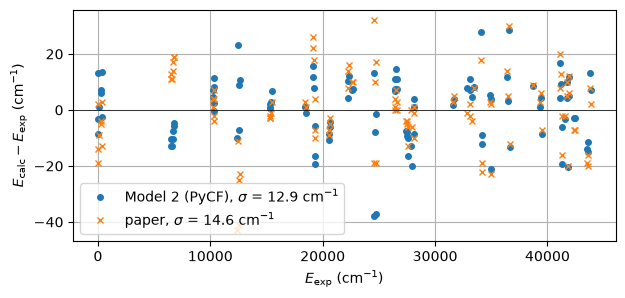

In [8]:
r = variants["ER_LIYF4_FREE_ION_REFIT (rounded)"][1]
plt.figure(figsize=(7, 3))
plt.plot(e_exp, r, "o", ms=4, label=f"Model 2 (PyCF), $\\sigma$ = {sigma(r):.1f} cm$^{{-1}}$")
plt.plot(e_exp, residuals_paper, "x", ms=4, label=f"paper, $\\sigma$ = {sigma(residuals_paper):.1f} cm$^{{-1}}$")
plt.axhline(0, color="k", lw=0.5)
plt.xlabel(r"$E_{\rm exp}$ (cm$^{-1}$)"); plt.ylabel(r"$E_{\rm calc}-E_{\rm exp}$ (cm$^{-1}$)")
plt.legend(); plt.grid(True)
plt.savefig("pdfs_figures/Er_LiYF4_residuals.pdf", bbox_inches="tight")
plt.show()

#### Qubit embedding and level structure

The 364 states are embedded in 9 qubits with 148 uncoupled padding states. Energies are passed to Qibo in units of 20 000 cm$^{-1}$, so that the norm of the embedded Hamiltonian is $O(1)$ as for Model 1.
Two groupings are fixed here, before any DBQA run:
- **levels**: Kramers doublets, grouping tolerance 10$^{-3}$ cm$^{-1}$;
- **manifolds**: clusters of levels separated by more than 300 cm$^{-1}$, larger than every gap inside the ground multiplet $^4I_{15/2}$ (at most 203 cm$^{-1}$), so that $^4I_{15/2}$ is one manifold. They separate the free-ion scale (which multiplet) from the crystal-field scale (which level inside a multiplet);
- **clusters**: levels closer than 1 cm$^{-1}$ merged, for which we report the joint subspace fidelity as for the close pair of Model 1. The two lowest levels (0.36 cm$^{-1}$ apart) form such a cluster.

In [9]:
f11cf = ImportSLJM(pycf_matel_path("f11cf", "eryso"))
coeff = er_liyf4_pycf_coeff(ER_LIYF4_FREE_ION_REFIT)
tensors = [getattr(f11cf, name) for name in coeff]

energy_unit = 20000.0  # cm^-1, so that the norm of the embedded Hamiltonian is O(1)
h, n_physical = crystal_field_hamiltonian(tensors, coeff, energy_unit=energy_unit)
h_matrix = h.backend.to_numpy(h.matrix)
energies = np.linalg.eigvalsh(h_matrix)

# levels: Kramers doublets, grouped with 1e-3 cm^-1
tol_doublets = 1e-3 / energy_unit
doublets = group_levels(energies, tol_doublets)
# manifolds: clusters separated by more than 300 cm^-1, larger than every gap inside the ground multiplet
tol_manifolds = 300.0 / energy_unit
manifolds = group_levels(energies, tol_manifolds)
# clusters: levels closer than 1 cm^-1 merged, for the close pairs (e.g. the two lowest levels, 0.36 cm^-1 apart)
tol_clusters = 1.0 / energy_unit
clusters = group_levels(energies, tol_clusters)
inside, between = check_grouping_tolerance(energies, tol_doublets)
assert inside < tol_doublets < between
print(f"nqubits = {h.nqubits}, physical states = {n_physical}, padding states = {2**h.nqubits - n_physical}")
print(f"norm of the traceless part: {np.linalg.norm(h_matrix - np.trace(h_matrix)/len(h_matrix)*np.eye(len(h_matrix)), 2):.2f}")
print(f"fraction of non-zero matrix elements: {np.mean(np.abs(h_matrix) > 1e-12):.3f}")
for label, tol, groups in [("levels", tol_doublets, doublets), ("manifolds", tol_manifolds, manifolds)]:
    inside, between = check_grouping_tolerance(energies, tol)
    print(f"{label}: {len(groups) - 1} physical groups, largest splitting inside {energy_unit*inside:.2e} cm^-1, "
          f"tolerance {energy_unit*tol:.0e} cm^-1, smallest gap between {energy_unit*between:.2f} cm^-1")
level_energies = energy_unit * (np.array([energies[g[0]] for g in doublets]) - energies[0])
print("ground multiplet levels (cm^-1):", np.round(level_energies[:8], 2))
print("manifold sizes (doublets), first 12:", [len(g) // 2 for g in manifolds[:12]])

nqubits = 9, physical states = 364, padding states = 148


norm of the traceless part: 3.07
fraction of non-zero matrix elements: 0.056
levels: 182 physical groups, largest splitting inside 2.58e-10 cm^-1, tolerance 1e-03 cm^-1, smallest gap between 0.03 cm^-1
manifolds: 35 physical groups, largest splitting inside 8.14e+02 cm^-1, tolerance 3e+02 cm^-1, smallest gap between 313.06 cm^-1
ground multiplet levels (cm^-1): [  0.     0.36   5.98  44.91 247.7  283.76 320.2  339.21]
manifold sizes (doublets), first 12: [8, 7, 6, 5, 5, 2, 6, 4, 3, 2, 5, 6]


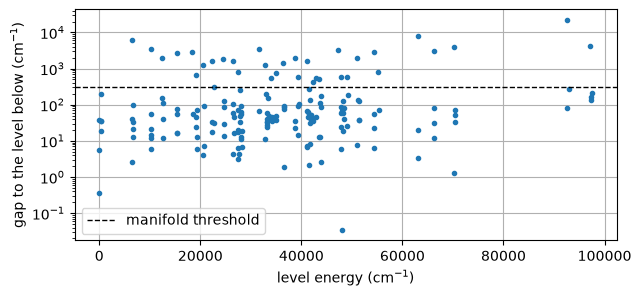

In [10]:
plt.figure(figsize=(7, 3))
gaps = np.diff(level_energies[:182])
plt.semilogy(level_energies[1:182], gaps, ".")
plt.axhline(300, color="k", ls="--", lw=1, label="manifold threshold")
plt.xlabel(r"level energy (cm$^{-1}$)"); plt.ylabel(r"gap to the level below (cm$^{-1}$)")
plt.legend(); plt.grid(True)
plt.savefig("pdfs_figures/Er_LiYF4_gaps.pdf", bbox_inches="tight")
plt.show()

In [11]:
with open("simulation_results/Er_LiYF4_hamiltonian.pickle", "wb") as file:
    pickle.dump(
        dict(
            parameters=dict(paper=ER_LIYF4_COUTO1998, model_2=ER_LIYF4_FREE_ION_REFIT, refit_all=variants["refit all"][0]),
            sigma={label: sigma(r) for label, (p, r) in variants.items()},
            sigma_paper=sigma(residuals_paper),
            energy_unit=energy_unit,
            energies=energies,
            doublets=doublets,
            manifolds=manifolds,
        ),
        file,
    )